<div dir="rtl">

# מפגש 2 · מנתונים גולמיים לקורפוס
**אחזור וסינון מידע (5020271) · SCE אשדוד**

המחברת של היום בונה את הצינור: **טקסט גולמי ← טוקנים ← נרמול ← קורפוס.**

| חלק | מה עושים | מתי |
|---|---|---|
| 1 | טוענים קורפוס הדגמה | ביחד, שיתוף מסך |
| 2 | טוקנייזר ונרמול: כמה מילים שונות נשארות? | ביחד |
| 3 | חוק זיפף בגרף | ביחד |
| 4 | עברית: מורידים תחיליות, ורואים מה נשבר | ביחד + TODO |
| 5 | מה נחשב מסמך? שתי הגדרות, השוואה | ביחד — הלב של תרגיל 1 |
| 6 | **הקורפוס שלכם**: טוענים מ-Hugging Face, שומרים 300 מסמכים נקיים | עבודה בקבוצות |

**איך עובדים:** `File → Save a copy in Drive`, ואז מריצים תא אחרי תא (`Shift+Enter`).
בתאים שמסומנים ✍️ **כותבים תחזית לפני שמריצים.** זה לא בשביל ציון היום — זה בדיוק מה שתעשו ב-commit התחזית של תרגיל 1.

הפתרונות ל-TODO נמצאים בתחתית המחברת. אל תפתחו לפני סוף המפגש.

</div>

In [3]:
# הגדרה — רץ פעם אחת (כ-20 שניות)
!pip -q install datasets nltk

import re, json, random
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from nltk.stem import PorterStemmer
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

random.seed(42)
pd.set_option("display.max_colwidth", 120)
print("מוכן ✓")

מוכן ✓


<div dir="rtl">

## חלק 1 · קורפוס הדגמה

לקורפוס ההדגמה בחרנו **20 Newsgroups**: הודעות אמיתיות מקבוצות דיון באינטרנט, משנות ה-90. זה מבחן ותיק בתחום אחזור המידע, והוא מלוכלך בדיוק כמו שצריך:
ציטוטים מהודעות קודמות (שורות שמתחילות ב-`>`), חתימות, כתובות מייל, מספרים, וקיצורים.

לוקחים ארבע קבוצות דיון: מכוניות, חלל, רפואה וגרפיקה.

</div>

In [4]:
CATEGORIES = ["rec.autos", "sci.space", "sci.med", "comp.graphics"]

def load_demo_corpus():
    """20 Newsgroups — headers removed, quotes and signatures kept on purpose."""
    from sklearn.datasets import fetch_20newsgroups
    data = fetch_20newsgroups(subset="train", categories=CATEGORIES,
                              remove=("headers",), shuffle=True, random_state=42)
    docs = []
    for i, (text, label) in enumerate(zip(data.data, data.target)):
        if text.strip():
            docs.append({"id": f"ng{i:05d}",
                         "title": data.target_names[label],
                         "text": text})
    return docs

try:
    demo_docs = load_demo_corpus()
    print(f"נטענו {len(demo_docs):,} הודעות מ-20 Newsgroups")
except Exception as e:
    # גיבוי: אם ההורדה נכשלה (רשת) — דוגמה קטנה שנכתבה לצורך ההדגמה בלבד, לא נתונים אמיתיים
    print("ההורדה נכשלה, ממשיכים עם דוגמה קטנה:", type(e).__name__)
    demo_docs = [
        {"id": "toy01", "title": "rec.autos", "text": "In article <123@abc.edu> john@abc.edu writes:\n> My 1991 Civic engine stalls at idle.\n> Any ideas?\n\nCheck the IAC valve. Mine did the same at 90,000 miles.\nCleaning it fixed it for $0.\n\n-- \nDave, Toronto"},
        {"id": "toy02", "title": "sci.space", "text": "The US launch schedule slipped again. NASA says the 737-sized payload\nwill fly in 1994.\n\nWe (us, the taxpayers) keep paying for delays."},
        {"id": "toy03", "title": "sci.med", "text": "> Is 4,000 mg of vitamin C a day safe?\n\nAt 4000 mg most people get stomach upset.\nAsk your doctor before taking megadoses."},
        {"id": "toy04", "title": "comp.graphics", "text": "Looking for C++ code to render JPEG files on a 486.\nC is fine too, but C++ preferred.\n\nThanks in advance!"},
    ]

df_demo = pd.DataFrame(demo_docs)
df_demo["title"].value_counts()

נטענו 2,361 הודעות מ-20 Newsgroups


,count
title,
sci.med,594
sci.space,593
rec.autos,592
comp.graphics,582


In [5]:
# איך נראה מסמך אחד? (מריצים כמה פעמים — כל פעם הודעה אחרת)
doc = random.choice(demo_docs)
print(doc["id"], "·", doc["title"])
print("-" * 60)
print(doc["text"][:1200])

ng00457 · comp.graphics
------------------------------------------------------------

Hi! Everyone,

Because no one has touched the problem I posted last week, I guess
my question was not so clear. Now I'd like to describe it in detail:

The offset of an ellipse is the locus of the center of a circle which
rolls on the ellipse. In other words, the distance between the ellipse
and its offset is same everywhere.

This problem comes from the geometric measurement when a probe is used.
The tip of the probe is a ball and the computer just outputs the
positions of the ball's center. Is the offset of an ellipse still
an ellipse? The answer is no! Ironically, DMIS - an American Indutrial
Standard says it is ellipse. So almost all the software which was
implemented on the base of DMIS was wrong. The software was also sold
internationaly. Imagine, how many people have or will suffer from this bug!!!
How many qualified parts with ellipse were/will be discarded? And most
importantly, how many defe

<div dir="rtl">

## חלק 2 · טוקנייזר ונרמול

הטוקנייזר הוא שורה אחת: `re.findall(r"\w+", text)` — כל רצף של אותיות, ספרות וקו תחתון.

אחר כך ארבעה שלבי נרמול, אחד על השני:
1. **lower** — אותיות קטנות
2. **no numbers** — מוחקים טוקנים שהם רק ספרות
3. **no stopwords** — מוחקים מילות עצירה (the, of, and…)
4. **stem** — גיזרון (Porter): `engines` → `engin`

✍️ **תחזית לפני ההרצה:** באיזה שלב אוצר המילים (מספר המילים השונות) ירד **הכי הרבה**? כתבו בתא הבא.

</div>

In [6]:
# ✍️ התחזית שלי:
my_prediction = """
השלב שיוריד הכי הרבה מילים שונות: השלב הוא שלב מספר 6
כי: שלב מספר 6 יוריד הכי הרבה כי הוא לא קיים
"""

In [7]:
stemmer = PorterStemmer()

def tokenize(text):
    return re.findall(r"\w+", text)

def normalize(tokens, lower=True, drop_numbers=True, drop_stop=True, stem=True):
    out = tokens
    if lower:
        out = [t.lower() for t in out]
    if drop_numbers:
        out = [t for t in out if not t.isdigit()]
    if drop_stop:
        out = [t for t in out if t.lower() not in ENGLISH_STOP_WORDS]
    if stem:
        out = [stemmer.stem(t) for t in out]
    return out

STAGES = {
    "raw":          dict(lower=False, drop_numbers=False, drop_stop=False, stem=False),
   # "+ lower":      dict(lower=True,  drop_numbers=False, drop_stop=False, stem=False),
    "+ no numbers": dict(lower=True,  drop_numbers=True,  drop_stop=False, stem=False),
    "+ no stopwords": dict(lower=True, drop_numbers=True, drop_stop=True,  stem=False),
    "+ stem":       dict(lower=True,  drop_numbers=True,  drop_stop=True,  stem=True),
}

def vocab_table(docs, stages=STAGES):
    raw_tokens = [tokenize(d["text"]) for d in docs]
    rows, prev = [], None
    for name, kw in stages.items():
        vocab, n_tokens = Counter(), 0
        for toks in raw_tokens:
            norm = normalize(toks, **kw)
            vocab.update(norm)
            n_tokens += len(norm)
        v = len(vocab)
        rows.append({"stage": name, "tokens": n_tokens, "unique words": v,
                     "drop vs. previous": "" if prev is None else f"{(prev - v) / prev:.0%}"})
        prev = v
    return pd.DataFrame(rows)

vocab_table(demo_docs)

,stage,tokens,unique words,drop vs. previous
0,raw,599001,44310,
1,+ no numbers,577387,32560,27%
2,+ no stopwords,317194,32255,1%
3,+ stem,317194,24364,24%


<div dir="rtl">

**מה לראות בטבלה:** באיזה שלב הירידה הכי גדולה? האם צדקתם?

ועכשיו הצד השני של המטבע. כל נרמול **מאחד** מילים — ולפעמים מאחד דברים שלא היו צריכים להתאחד. התא הבא מראה מה הגיזרון איחד:

</div>

In [8]:
# אילו מילים שונות הפכו לאותו גזע?
all_tokens = [t.lower() for d in demo_docs for t in tokenize(d["text"]) if t.isalpha()]
freq = Counter(all_tokens)
by_stem = {}
for w in freq:
    by_stem.setdefault(stemmer.stem(w), set()).add(w)

# גזעים שאיחדו מילים עם משמעות שונה — דוגמאות שבוחרים לבדוק
for s in ["univers", "gener", "organ", "polic", "new", "us"]:
    if s in by_stem:
        print(f"{s:>8} ← {sorted(by_stem[s], key=lambda w: -freq[w])[:8]}")

 univers ← ['university', 'universe', 'universities', 'universal', 'universally']
   gener ← ['general', 'generally', 'generation', 'generate', 'generated', 'generic', 'generating', 'generates']
   organ ← ['organization', 'organizations', 'organisms', 'organism', 'organized', 'organic', 'organs', 'organ']
   polic ← ['police']
     new ← ['new']
      us ← ['us']


In [9]:
# ומה ה-lower מחק? מילים שמשנות משמעות לפי אותיות גדולות
raw_freq = Counter(t for d in demo_docs for t in tokenize(d["text"]))
for w in ["US", "us", "IT", "it", "AIDS", "aids", "Apple", "apple"]:
    print(f"{w:>6}: {raw_freq[w]:>5}")

    US:   280
    us:   273
    IT:    18
    it:  5523
  AIDS:    86
  aids:     1
 Apple:    37
 apple:    33


<div dir="rtl">

**TODO 1 (2 דקות):** מצאו בקורפוס ההדגמה מילה אחת שהנרמול **הרס** — שתי מילים שונות שהפכו לאותו טוקן, או מידע שנמחק (מספר חשוב, שם דגם, C++).
כתבו אותה בצ'אט. זה בדיוק סוג המקרים שתאספו בתרגיל 1 (חמישה מקרים אמיתיים מהקורפוס שלכם).

</div>

In [10]:
# TODO 1 — חפשו כאן. רמז: הדפיסו הקשר של מילה בתוך הטקסט
def kwic(word, docs, width=50, n=5):
    """Keyword in context — מראה איפה מילה מופיעה."""
    shown = 0
    for d in docs:
        for m in re.finditer(rf"\b{re.escape(word)}\b", d["text"]):
            s, e = max(0, m.start() - width), m.end() + width
            print(f"{d['id']}: ...{d['text'][s:e]!r}...")
            shown += 1
            if shown >= n:
                return

kwic("US", demo_docs)

ng00002: ...'eland.\n6 issues (one year sub.): UK 10.00 pounds, US$20 surface (add US$8 airmail).\nACCESS/VISA/MASTER'...
ng00002: ...'e year sub.): UK 10.00 pounds, US$20 surface (add US$8 airmail).\nACCESS/VISA/MASTERCARD accepted (give'...
ng00015: ...'ay.  I thought\nAudi stopped selling wagons in the US after the 5000.  This is exactly the\ntype of vehi'...
ng00042: ...' of the\nBritish visiting cosmonaut to Mir.\n   Now US firms are starting to put paid advertisements on '...
ng00056: ...'Government or International\nBureaucracies.\tIn the US that means NASA.  If you have basic information\nr'...


<div dir="rtl">

## חלק 3 · חוק זיפף

מסדרים את כל המילים לפי תדירות. המילה הנפוצה ביותר מקבלת דירוג 1, השנייה דירוג 2, וכן הלאה.
**חוק זיפף:** התדירות של מילה הפוכה בערך לדירוג שלה — מילה בדירוג 2 מופיעה בערך חצי מהפעמים של המילה בדירוג 1.

בגרף רגיל זה נראה כמו "L" — אי אפשר לראות כלום. לכן **שני הצירים בסקאלה לוגריתמית**, ואז זיפף נראה כמו **קו ישר יורד** עם שיפוע של בערך 1-.

</div>

5 המילים הנפוצות: ['the', 'to', 'a', 'of', 'and']


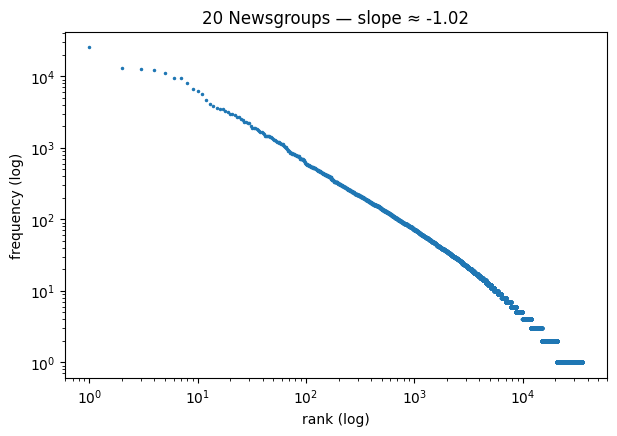

In [11]:
def zipf_plot(docs, title="Zipf", ax=None):
    counts = Counter(t.lower() for d in docs for t in tokenize(d["text"]))
    freqs = np.array(sorted(counts.values(), reverse=True))
    ranks = np.arange(1, len(freqs) + 1)
    # שיפוע על הטווח האמצעי (ההתחלה והזנב רועשים)
    lo, hi = (10, min(len(freqs), 5000)) if len(freqs) > 50 else (0, len(freqs))
    slope = np.polyfit(np.log10(ranks[lo:hi]), np.log10(freqs[lo:hi]), 1)[0]
    ax = ax or plt.gca()
    ax.loglog(ranks, freqs, ".", markersize=3)
    ax.set_xlabel("rank (log)")
    ax.set_ylabel("frequency (log)")
    ax.set_title(f"{title} — slope ≈ {slope:.2f}")
    top = [w for w, _ in counts.most_common(5)]
    print("5 המילים הנפוצות:", top)
    return slope

plt.figure(figsize=(7, 4.5))
zipf_plot(demo_docs, "20 Newsgroups")
plt.show()

<div dir="rtl">

**שאלה לצ'אט:** חמש המילים הנפוצות הן כמעט תמיד מילות עצירה. מה זה אומר על מילה שמופיעה **בכל** המסמכים — כמה היא עוזרת לחיפוש?
(זו בדיוק השאלה של המאמר של Spärck Jones משנת 1972 — הנושא של המפגש הבא.)

</div>

<div dir="rtl">

## חלק 4 · עברית: אותיות השימוש

הפונקציה הבאה מורידה מתחילת מילה את האותיות **משה וכלב** (מ, ש, ה, ו, כ, ל, ב) — עד שתיים, כל עוד נשארות לפחות שתי אותיות.

✍️ **תחזית לפני ההרצה:** אילו מהמילים ברשימה ייצאו **נכון**, ואילו ייהרסו?

</div>

In [12]:
PREFIXES = "משהוכלב"

def strip_prefixes(word, max_strip=2, min_len=2):
    """Naive Hebrew prefix stripping: remove up to max_strip prefix letters."""
    stripped = 0
    while stripped < max_strip and len(word) > min_len and word[0] in PREFIXES:
        word = word[1:]
        stripped += 1
    return word

words = ["ובבית", "הבית", "לבית", "מהבית", "שבבית",   # כאן יש תחיליות אמיתיות
         "מלך", "כלב", "שלום", "ביטוח", "הסכם", "ומשפחה", "משפחה", "בשורה"]

for w in words:
    print(f"{w:>8}  →  {strip_prefixes(w)}")

   ובבית  →  בית
    הבית  →  ית
    לבית  →  ית
   מהבית  →  בית
   שבבית  →  בית
     מלך  →  לך
     כלב  →  לב
    שלום  →  ום
   ביטוח  →  יטוח
    הסכם  →  סכם
  ומשפחה  →  שפחה
   משפחה  →  פחה
   בשורה  →  ורה


<div dir="rtl">

**מה קרה:** "ובבית" יצא נכון — אבל "הבית" הפך ל"ית", "מלך" ל"לך", "כלב" ל"לב", "שלום" ל"ום", "משפחה" ל"פחה".
הכלל הנאיבי לא יודע להבדיל בין **אות שימוש** לבין **אות שורש** שבמקרה נמצאת בהתחלה.

**TODO 2 (בקבוצות, או בבית):** הציעו כלל טוב יותר. רעיון: להוריד תחילית **רק אם מה שנשאר הוא מילה שכבר קיימת** באוצר המילים.
ואז — מצאו מילה אחת שגם הכלל המשופר שלכם שובר. (תמיד יש.)

</div>

In [13]:
# TODO 2 — הכלל המשופר שלכם
# אוצר מילים לדוגמה. בקורפוס שלכם: כל המילים שמופיעות בו
known_words = {"בית", "מלך", "כלב", "לב", "לך", "שלום", "ביטוח", "הסכם", "משפחה", "שורה", "פחה"}

def strip_prefixes_v2(word, vocab):
    # כתבו כאן
    return word

for w in words:
    print(f"{w:>8}  →  {strip_prefixes_v2(w, known_words)}")

   ובבית  →  ובבית
    הבית  →  הבית
    לבית  →  לבית
   מהבית  →  מהבית
   שבבית  →  שבבית
     מלך  →  מלך
     כלב  →  כלב
    שלום  →  שלום
   ביטוח  →  ביטוח
    הסכם  →  הסכם
  ומשפחה  →  ומשפחה
   משפחה  →  משפחה
   בשורה  →  בשורה


<div dir="rtl">

## חלק 5 · מה נחשב מסמך אחד?

זו **ההחלטה הראשונה** של כל מנוע חיפוש, והיא הלב של תרגיל 1.

בקורפוס ההדגמה, כל הודעה מכילה שני סוגי טקסט: מה שהכותב כתב, ו**ציטוטים** מהודעות קודמות (שורות שמתחילות ב-`>`). ויש בה כמה פסקאות.
אז מה המסמך?

| הגדרה | מסמך = | היתרון | הבעיה |
|---|---|---|---|
| **A · יחידה גדולה** | ההודעה כולה, כמו שהיא | כל ההקשר במקום אחד | מחזירים עמוד שלם; ציטוטים נספרים פעמיים |
| **B · יחידה קטנה** | כל פסקה שהכותב עצמו כתב (בלי ציטוטים, בלי חתימה) | תשובה ממוקדת | פסקה בלי ההקשר שלה |

✍️ **תחזית לפני ההרצה:** באיזו הגדרה יהיו **יותר מסמכים**? יותר **מילים שונות**? אורך ממוצע ארוך יותר? ולמה?

</div>

In [14]:
# ✍️ התחזית שלי (A מול B):
my_prediction_units = """
יותר מסמכים: ...
יותר מילים שונות: ...
למה: ...
"""

In [15]:
QUOTE_LINE = re.compile(r"^\s*(>|\|)|wr(o|i)tes?:\s*$|^In article <", re.IGNORECASE)
SIGNATURE = re.compile(r"\n--\s*\n.*", re.DOTALL)      # הכל אחרי "-- " בשורה נפרדת

def units_A(doc):
    """A: the whole message is one document."""
    return [{"id": doc["id"], "title": doc["title"], "text": doc["text"].strip()}]

def units_B(doc, min_tokens=8):
    """B: every paragraph the author wrote (no quotes, no signature) is a document."""
    text = SIGNATURE.sub("", doc["text"])
    own_lines = [ln for ln in text.splitlines() if not QUOTE_LINE.search(ln)]
    paragraphs = re.split(r"\n\s*\n", "\n".join(own_lines))
    out = []
    for k, p in enumerate(paragraphs):
        p = p.strip()
        if len(tokenize(p)) >= min_tokens:
            out.append({"id": f"{doc['id']}_p{k}", "title": doc["title"], "text": p})
    return out

def build(docs, unit_fn):
    return [u for d in docs for u in unit_fn(d)]

def corpus_stats(corpus, name):
    lengths = [len(tokenize(d["text"])) for d in corpus]
    vocab = Counter(t.lower() for d in corpus for t in tokenize(d["text"]))
    texts = [d["text"] for d in corpus]
    return {"definition": name,
            "documents": len(corpus),
            "avg length (tokens)": round(float(np.mean(lengths)), 1),
            "unique words": len(vocab),
            "exact duplicates": len(texts) - len(set(texts))}

corpus_A = build(demo_docs, units_A)
corpus_B = build(demo_docs, units_B)
pd.DataFrame([corpus_stats(corpus_A, "A · whole message"),
              corpus_stats(corpus_B, "B · own paragraphs")])

,definition,documents,avg length (tokens),unique words,exact duplicates
0,A · whole message,2361,253.7,35786,2
1,B · own paragraphs,9279,45.2,29757,204


<div dir="rtl">

**לקרוא את הטבלה:** האם צדקתם? ושימו לב לשורה **"unique words"** — ב-B יש פחות. איפה הן נעלמו?
(רמז: מה עוד מחקנו חוץ מלחתוך לפסקאות?)

עכשיו אותו חיפוש פשוט על שני הקורפוסים. מה מקבל המשתמש בכל אחד?

</div>

In [16]:
def simple_search(query, corpus, k=3):
    """Return the k documents with the most query-word hits (lowercased, no stemming)."""
    q = set(t.lower() for t in tokenize(query))
    scored = []
    for d in corpus:
        toks = [t.lower() for t in tokenize(d["text"])]
        hits = sum(1 for t in toks if t in q)
        if hits:
            scored.append((hits, d))
    return [d for _, d in sorted(scored, key=lambda x: -x[0])[:k]]

QUERY = "engine oil change"
for name, corpus in [("A", corpus_A), ("B", corpus_B)]:
    top = simple_search(QUERY, corpus, k=1)
    print(f"=== הגדרה {name} · התוצאה הראשונה ===")
    if top:
        print(f"[{top[0]['id']}] {len(tokenize(top[0]['text']))} טוקנים")
        print(top[0]["text"][:500], "\n")
    else:
        print("אין אף מסמך עם מילות השאילתה\n")

=== הגדרה A · התוצאה הראשונה ===
[ng00538] 4512 טוקנים
Archive-name: rec-autos/part5

[this article is one of a pair of articles containing commonly
asked automotive questions; the other article contains questions
more geared to the automotive enthusiast, and so is not crossposted
to misc.consumers.  -- rpw]

   [changes as of 14 April 1993: revised brake fluid section, as
    non-silicone DOT-5 fluids are now apparently available -- rpw]

                 Commonly Asked Automotive Questions


Tire Questions:

Q:  What do the funny numbers on the si 

=== הגדרה B · התוצאה הראשונה ===
[ng00538_p66] 167 טוקנים
The more noticeable designation is the oil weight.  This is either
    a single number (e.g., 30 weight) or a pair of numbers separated by
    the letter W (e.g., 10W30.)  The latter type is much more commonly
    used these days, and are the only type that most automobile
    manufacturers specify in operators manuals.  The first number in the
    designation (10W) is the apparent

<div dir="rtl">

**לדיון:** תוצאה ב-A — המשתמש צריך לקרוא הודעה שלמה, לפעמים עם ציטוט של מישהו אחר שבכלל לא עונה. תוצאה ב-B — ממוקדת, אבל לפעמים חסר לה מה ששאלו.

**אין הגדרה "נכונה".** יש הגדרה שמתאימה לשאלות שהמשתמשים שלכם ישאלו. זו ההחלטה שתנמקו בתרגיל 1, ושנחזור אליה במפגש 8 (RAG) תחת השם **chunking**.

</div>

<div dir="rtl">

## חלק 6 · הקורפוס שלכם — עבודה בקבוצות (45 דק')

**המטרה לסוף המפגש:** קובץ `corpus.jsonl` עם **לפחות 300 מסמכים נקיים**, ברפו של הקבוצה. זו ההתחלה של תרגיל 1.

1. מלאו למטה את שם הדאטהסט מ-Hugging Face (מהרשימה במודל) ואת שם עמודת הטקסט.
2. הריצו. אם יש שגיאה — התא הבא מדפיס את שמות העמודות, ומשם מתקנים.
3. כתבו `units_A` ו-`units_B` **שמתאימים לקורפוס שלכם** — מה אצלכם יחידה גדולה ומה קטנה?
4. **דקה 20:** שורה בצ'אט הכללי — כמה מסמכים יש לכם ומה ההגדרה שלכם למסמך.
5. שומרים, מורידים, מעלים לרפו.

> 💡 קבוצה שעוד אין לה קורפוס מאושר — מתחילה מקורפוס ההדגמה (`demo_docs`) ומחליפה אחר כך.

</div>

In [17]:
# ===== מלאו כאן =====
HF_DATASET = "BeIR/scifact"
HF_CONFIG  = "corpus"
SPLIT      = "corpus"
TEXT_COL   = "text"
TITLE_COL  = "title"
MAX_DOCS   = 3000
# =====================

import random
from datasets import load_dataset

def load_my_corpus():
    if not HF_DATASET:
        print("לא מולא HF_DATASET — ממשיכים עם קורפוס ההדגמה")
        return demo_docs

    ds = load_dataset(HF_DATASET, HF_CONFIG, split=SPLIT)
    print("עמודות:", ds.column_names, "| שורות:", f"{len(ds):,}")

    if TEXT_COL not in ds.column_names:
        raise KeyError(f"אין עמודה '{TEXT_COL}'. בחרו אחת מ: {ds.column_names}")

    ds = ds.shuffle(seed=42).select(range(min(MAX_DOCS, len(ds))))

    docs = []
    for i, row in enumerate(ds):
        text = row[TEXT_COL]

        if not isinstance(text, str) or not text.strip():
            continue

        title = str(row[TITLE_COL]) if TITLE_COL else ""

        docs.append({
            "id": f"doc{i:05d}",
            "title": title,
            "text": text
        })

    return docs

my_docs = load_my_corpus()

print(f"{len(my_docs):,} מסמכים נטענו")
print("-" * 60)
print(random.choice(my_docs)["text"][:800])

README.md:   0%|          | 0.00/10.4k [00:00<?, ?B/s]

corpus/corpus-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 4.47MB            

corpus/corpus-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating corpus split:   0%|          | 0/5183 [00:00<?, ? examples/s]

עמודות: ['_id', 'title', 'text'] | שורות: 5,183
3,000 מסמכים נטענו
------------------------------------------------------------
Recent evidence suggests that vitamin D intakes above current recommendations may be associated with better health outcomes. However, optimal serum concentrations of 25-hydroxyvitamin D [25(OH)D] have not been defined. This review summarizes evidence from studies that evaluated thresholds for serum 25(OH)D concentrations in relation to bone mineral density (BMD), lower-extremity function, dental health, and risk of falls, fractures, and colorectal cancer. For all endpoints, the most advantageous serum concentrations of 25(OH)D begin at 75 nmol/L (30 ng/mL), and the best are between 90 and 100 nmol/L (36-40 ng/mL). In most persons, these concentrations could not be reached with the currently recommended intakes of 200 and 600 IU vitamin D/d for younger and older adults, respectively. A comp


In [18]:
import re
import pandas as pd
import numpy as np
from collections import Counter

# פירוק טקסט למילים
def tokenize(text):
    return re.findall(r"\b\w+\b", text.lower())

# הגדרה A: כל תקציר מדעי הוא מסמך אחד
def my_units_A(doc):
    return [{
        "id": doc["id"],
        "title": doc["title"],
        "text": doc["text"].strip()
    }]

# הגדרה B: כל משפט הוא מסמך נפרד
def my_units_B(doc, min_tokens=8):
    parts = re.split(r"(?<=[.!?])\s+", doc["text"].strip())

    return [
        {
            "id": f"{doc['id']}_s{k}",
            "title": doc["title"],
            "text": part.strip()
        }
        for k, part in enumerate(parts)
        if len(tokenize(part)) >= min_tokens
    ]

# בניית הקורפוסים
def build(docs, unit_fn):
    return [unit for doc in docs for unit in unit_fn(doc)]

# חישוב נתונים סטטיסטיים
def corpus_stats(corpus, name):
    lengths = [len(tokenize(doc["text"])) for doc in corpus]
    words = [
        word
        for doc in corpus
        for word in tokenize(doc["text"])
    ]
    texts = [doc["text"] for doc in corpus]

    return {
        "definition": name,
        "documents": len(corpus),
        "avg length (tokens)": round(float(np.mean(lengths)), 1) if lengths else 0,
        "unique words": len(set(words)),
        "exact duplicates": len(texts) - len(set(texts))
    }

# יצירת שתי ההגדרות
my_A = build(my_docs, my_units_A)
my_B = build(my_docs, my_units_B)

# טבלת השוואה
pd.DataFrame([
    corpus_stats(my_A, "A"),
    corpus_stats(my_B, "B")
])

,definition,documents,avg length (tokens),unique words,exact duplicates
0,A,3000,212.2,27464,0
1,B,25769,24.5,27229,11


In [19]:
import re
import pandas as pd
from collections import Counter
from nltk.stem import PorterStemmer
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

stemmer = PorterStemmer()

def tokenize(text):
    return re.findall(r"\w+", text)

def normalize(tokens, lower=True, drop_numbers=True, drop_stop=True, stem=True):
    out = tokens
    if lower:
        out = [t.lower() for t in out]
    if drop_numbers:
        out = [t for t in out if not t.isdigit()]
    if drop_stop:
        out = [t for t in out if t.lower() not in ENGLISH_STOP_WORDS]
    if stem:
        out = [stemmer.stem(t) for t in out]
    return out

STAGES = {
    "raw": dict(lower=False, drop_numbers=False, drop_stop=False, stem=False),
    "+ lower": dict(lower=True, drop_numbers=False, drop_stop=False, stem=False),
    "+ no numbers": dict(lower=True, drop_numbers=True, drop_stop=False, stem=False),
    "+ no stopwords": dict(lower=True, drop_numbers=True, drop_stop=True, stem=False),
    "+ stem": dict(lower=True, drop_numbers=True, drop_stop=True, stem=True),
}

def vocab_table(docs, stages=STAGES):
    raw_tokens = [tokenize(d["text"]) for d in docs]
    rows, prev = [], None

    for name, kw in stages.items():
        vocab, n_tokens = Counter(), 0

        for toks in raw_tokens:
            norm = normalize(toks, **kw)
            vocab.update(norm)
            n_tokens += len(norm)

        v = len(vocab)

        rows.append({
            "stage": name,
            "tokens": n_tokens,
            "unique words": v,
            "drop vs. previous": "" if prev is None else f"{(prev - v) / prev:.0%}"
        })

        prev = v

    return pd.DataFrame(rows)

# טבלת הנרמול של הקורפוס שלנו
vocab_table(my_A)

,stage,tokens,unique words,drop vs. previous
0,raw,636548,31863,
1,+ lower,636548,27464,14%
2,+ no numbers,607160,26115,5%
3,+ no stopwords,379551,25837,1%
4,+ stem,379551,18488,28%


5 המילים הנפוצות: ['the', 'of', 'and', 'in', 'to']


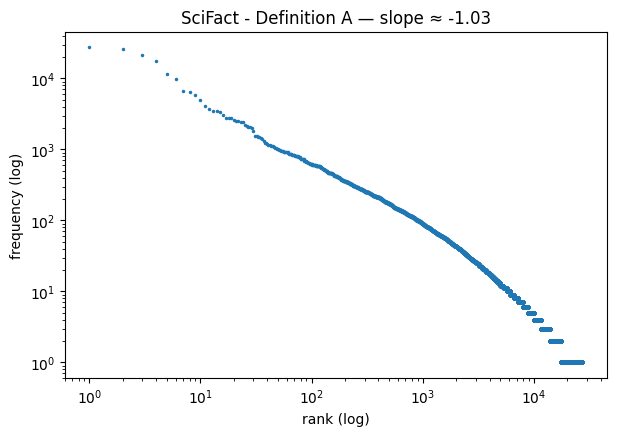

In [20]:
import matplotlib.pyplot as plt
import numpy as np
from collections import Counter

# פונקציית Zipf המקורית של המרצה
def zipf_plot(docs, title="Zipf", ax=None):
    counts = Counter(t.lower() for d in docs for t in tokenize(d["text"]))
    freqs = np.array(sorted(counts.values(), reverse=True))
    ranks = np.arange(1, len(freqs) + 1)

    # שיפוע על הטווח האמצעי
    lo, hi = (10, min(len(freqs), 5000)) if len(freqs) > 50 else (0, len(freqs))
    slope = np.polyfit(np.log10(ranks[lo:hi]), np.log10(freqs[lo:hi]), 1)[0]

    ax = ax or plt.gca()
    ax.loglog(ranks, freqs, ".", markersize=3)
    ax.set_xlabel("rank (log)")
    ax.set_ylabel("frequency (log)")
    ax.set_title(f"{title} — slope ≈ {slope:.2f}")

    top = [w for w, _ in counts.most_common(5)]
    print("5 המילים הנפוצות:", top)

    return slope

# גרף Zipf של קורפוס SciFact שלנו
plt.figure(figsize=(7, 4.5))
zipf_plot(my_A, "SciFact - Definition A")
plt.show()

In [21]:
import re
import json

# בחירת הגדרה A: כל תקציר מדעי הוא מסמך אחד
CHOSEN = my_A
N_KEEP = 300

# ניקוי בסיסי של הטקסט
def clean(text):
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()

# הסרת מסמכים קצרים וכפילויות
seen, final = set(), []

for d in CHOSEN:
    t = clean(d["text"])

    if len(tokenize(t)) >= 5 and t not in seen:
        seen.add(t)
        final.append({**d, "text": t})

# שמירת 300 מסמכים
final = final[:N_KEEP]

with open("corpus.jsonl", "w", encoding="utf-8") as f:
    for d in final:
        f.write(json.dumps(d, ensure_ascii=False) + "\n")

print(f"נשמרו {len(final)} מסמכים ב-corpus.jsonl")

if len(final) < N_KEEP:
    print("⚠️ פחות מ-300 — הגדילו את MAX_DOCS או בחרו הגדרה אחרת")

נשמרו 300 מסמכים ב-corpus.jsonl


In [22]:
# הורדה למחשב → ואז GitHub Desktop: להעתיק לתיקיית הרפו, commit, push
from google.colab import files
files.download("corpus.jsonl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<div dir="rtl">

---
## מה לוקחים לתרגיל 1

| מה | מאיפה במחברת |
|---|---|
| commit תחזית (לפני הרצה!) | התאים ✍️ בחלקים 2 ו-5 |
| טבלת שתי ההגדרות | `corpus_stats` בחלק 6 |
| טבלת הנרמול | `vocab_table` בחלק 6 |
| 5 מקרים שהצינור טיפל בהם לא נכון | `kwic` מחלק 2, על הקורפוס שלכם |
| `corpus.jsonl` | התא האחרון בחלק 6 |

הדף המלא של התרגיל במודל.

</div>

<div dir="rtl">

---
---
# 🔒 פתרונות — לפתוח רק בסוף המפגש

</div>

<div dir="rtl">

### TODO 1 · מה הנרמול הרס — תשובות טובות
- **US / us** — ארה"ב ו"אנחנו" מתאחדים ב-lower. מי שמחפש מידע על ארה"ב מקבל כל הודעה עם "us".
- **AIDS / aids** — המחלה ופועל ("עוזר"). בקבוצת הרפואה זה מסוכן במיוחד.
- **מספרים** — `no numbers` מוחק "486" (מעבד), "737" (מטוס), שנים. אחרי זה אי אפשר לחפש דגם.
- **C++** — `\w+` הופך אותו ל-"C", ואז הוא מתאחד עם השפה C.
- **גיזרון** — `university` ו-`universe` נופלים שניהם ל-`univers`; `general` ו-`generate` ל-`gener`.

</div>

In [23]:
# TODO 2 · פתרון: מורידים תחילית רק אם השארית היא מילה מוכרת
def strip_prefixes_v2(word, vocab, max_strip=2, min_len=2):
    if word in vocab:                   # המילה עצמה מוכרת — לא נוגעים
        return word
    w = word
    for _ in range(max_strip):
        if len(w) > min_len and w[0] in PREFIXES:
            w = w[1:]
            if w in vocab:
                return w
        else:
            break
    return word                          # לא מצאנו שארית מוכרת — משאירים כמו שהיה

for w in words:
    print(f"{w:>8}  →  {strip_prefixes_v2(w, known_words)}")

# ומה הכלל הזה עדיין שובר?
# "בשורה" (חדשה טובה) הופכת ל"שורה" אם "בשורה" לא באוצר המילים.
# ו"מלך" נשמר רק כי הוספנו אותו ידנית ל-known_words; בקורפוס קטן הרבה מילים לא יופיעו.
print("בשורה →", strip_prefixes_v2("בשורה", known_words))

   ובבית  →  בית
    הבית  →  בית
    לבית  →  בית
   מהבית  →  בית
   שבבית  →  בית
     מלך  →  מלך
     כלב  →  כלב
    שלום  →  שלום
   ביטוח  →  ביטוח
    הסכם  →  הסכם
  ומשפחה  →  משפחה
   משפחה  →  משפחה
   בשורה  →  שורה
בשורה → שורה


<div dir="rtl">

### חלק 5 · למה ב-B יש פחות מילים שונות?
כי B לא רק חותך לפסקאות: הוא גם **מוחק ציטוטים וחתימות**, ופסקאות קצרות מ-8 טוקנים.
חתימות מלאות במילים נדירות (שמות, כתובות מייל, מוסדות), ולכן אוצר המילים יורד.
**לקח לתרגיל:** כשמשווים שתי הגדרות, צריך לדעת מה בדיוק שונה ביניהן — אחרת מייחסים את ההבדל לסיבה הלא נכונה.

</div>